In [47]:
import numpy as np
import pandas as pd
from sklearn.datasets import make_blobs, make_gaussian_quantiles
import matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.cluster import DBSCAN

In [3]:
rand = 42
sample_amount = 40_000
feature_amount = 20

In [4]:
#dataset 1 (8 blobs)

X, cluster_id = make_blobs(n_samples=sample_amount, n_features=feature_amount, centers=8, cluster_std=1.2, random_state=rand,)
df = pd.DataFrame(X, columns=[f"f{i}" for i in range(X.shape[1])])

In [26]:
#dataset 2 (1 cluster with correlated features)

mean = np.zeros(feature_amount)
cov = np.random.default_rng(rand).uniform(-0.5, 0.5, size=(feature_amount, feature_amount))
cov = cov @ cov.T
X = np.random.default_rng(rand).multivariate_normal(mean, cov, size=sample_amount)
df = pd.DataFrame(X, columns=[f"f{i}" for i in range(X.shape[1])])

In [28]:
#dataset 3 (nested/ non-linear structure)

X, y = make_gaussian_quantiles(n_samples=sample_amount, n_features=feature_amount, n_classes=3, random_state=rand)
df = pd.DataFrame(X, columns=[f"f{i}" for i in range(X.shape[1])])

In [5]:
#1 | extreme        | push feature values far outside range
#2 | gaussian       | add jitter to feature values
#3 | shuffle        | swap feature values with other row's
#4 | uniform_random | replace feature values with values from data range (ignores correlation)

#IMPORTANT: WHEN ADDING NOISE MORE THAN ONCE, CHANGE THE SEED OR IT WILL CHOOSE SAME COLUMNS TO ADD NOISE TOO AND OVERIDE PREVIOUS NOISE ADDITIONS

def inject_noise(df, noise_frac=0.1, method=1, n_features_affected=None, seed=rand, mask=None):

    rng = np.random.default_rng(seed)
    noisy = df.copy()
    cols_all = df.columns
    n = len(df)
    n_noise = int(n * noise_frac)
    noise_idx = rng.choice(df.index, size=n_noise, replace=False)
    if mask is None:
        mask = np.zeros(n, dtype=bool)
    mask[df.index.get_indexer(noise_idx)] = True

    for row_id in noise_idx:
        if n_features_affected is None:
            cols = cols_all
        else:
            cols = rng.choice(cols_all, size=n_features_affected, replace=False)

        for col in cols:
            std = df[col].std()

            match method:
                case 1:
                    direction = rng.choice([-1, 1])
                    magnitude = rng.uniform(6, 12)
                    noisy.loc[row_id, col] = df.loc[row_id, col] + direction * std * magnitude

                case 2:
                    noisy.loc[row_id, col] = df.loc[row_id, col] + rng.normal(0, std * 3)

                case 3:
                    donor_id = rng.choice(df.index)
                    noisy.loc[row_id, col] = df.loc[donor_id, col]

                case 4:
                    lo, hi = df[col].min(), df[col].max()
                    noisy.loc[row_id, col] = rng.uniform(lo, hi)

                case _:
                    raise ValueError(f"Unknown method: {method}")

    return noisy, mask

In [6]:
noisy_df, true_mask = inject_noise(df, noise_frac=0.3, method=1)

In [39]:
print(len(np.array(np.where(true_mask == True)).reshape(-1))/len(true_mask))

0.28


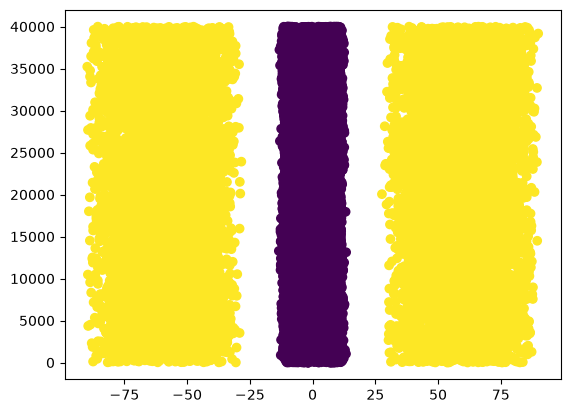

In [7]:
plt.scatter(noisy_df.iloc[:, 0], df.index, c=true_mask)
plt.scatter
plt.show()

In [40]:
#metaparam
iqr_fence = 1.5
col_ratio = 0.8

suspects = np.zeros(len(noisy_df), dtype=int)
false_pos = 0
false_neg = 0

for col in noisy_df.columns:
    Q1 = np.percentile(noisy_df[col], 25)
    Q3 = np.percentile(noisy_df[col], 75)
    IQR = Q3 - Q1
    lower_bound_iqr = Q1 - iqr_fence * IQR
    upper_bound_iqr = Q3 + iqr_fence * IQR
    outliers = (noisy_df[col] < lower_bound_iqr) | (noisy_df[col] > upper_bound_iqr)
    suspects += outliers

predicted_mask = suspects > len(noisy_df.columns) * col_ratio

print(confusion_matrix(true_mask, predicted_mask))
print(classification_report(true_mask, predicted_mask, target_names=["Normal", "Outlier"]))

[[28000     0]
 [    0 12000]]
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00     28000
     Outlier       1.00      1.00      1.00     12000

    accuracy                           1.00     40000
   macro avg       1.00      1.00      1.00     40000
weighted avg       1.00      1.00      1.00     40000



In [ ]:
#metaparam
contam = 'auto'

isolation_forest = IsolationForest(n_estimators=200, contamination=contam, n_jobs=-1, random_state=rand)

predicted_mask = isolation_forest.fit_predict(noisy_df) == -1

print(confusion_matrix(true_mask, predicted_mask))
print(classification_report(true_mask, predicted_mask, target_names=["Normal", "Outlier"]))

[[28000     0]
 [    0 12000]]
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00     28000
     Outlier       1.00      1.00      1.00     12000

    accuracy                           1.00     40000
   macro avg       1.00      1.00      1.00     40000
weighted avg       1.00      1.00      1.00     40000



k=1: inertia=800000.0000000002
k=2: inertia=777994.2913541032
k=3: inertia=759232.1797563059
k=4: inertia=741699.5102310143
k=5: inertia=725434.9370916851
k=6: inertia=717909.3469189598
k=7: inertia=712107.1670496445
k=8: inertia=701012.1190799088
k=9: inertia=691837.8485202604
k=10: inertia=690044.5319780469
k=11: inertia=684090.5227413146
k=12: inertia=677232.4203749386
k=13: inertia=671603.8334467467
k=14: inertia=666927.7867738991
k=15: inertia=662409.6642458546
k=16: inertia=657783.983488392
k=17: inertia=653854.5154762071
k=18: inertia=650225.7261959879
k=19: inertia=646712.4259246694
k=20: inertia=642812.4052712686


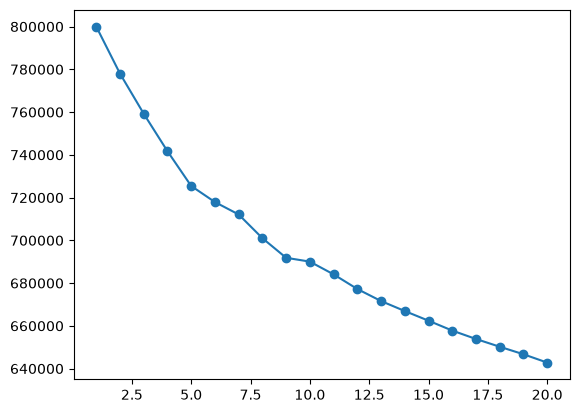

In [42]:
#metaparam
cluster_start = 1
cluster_end = 20

noisy_scaled = StandardScaler().fit_transform(noisy_df)
inertias = []

for i in range(cluster_start, cluster_end + 1):
    k_means = KMeans(n_clusters=i, random_state=rand, n_init="auto")
    k_means.fit(noisy_scaled)

    inertias.append(k_means.inertia_)
    print(f"k={i}: inertia={k_means.inertia_}")

plt.plot(range(cluster_start, cluster_end + 1), inertias, marker="o")
plt.show()

In [46]:
#metaparam
cluster_start = 2
cluster_end = 10
init = 10

noisy_scaled = StandardScaler().fit_transform(noisy_df)

for i in range(cluster_start, cluster_end + 1):
    k_means = KMeans(n_clusters=i, n_init=init, random_state=rand)

    predicted_labels = k_means.fit_predict(noisy_scaled)
    silhouette = silhouette_score(noisy_scaled, predicted_labels)
    print(f"k={i}: {silhouette}")

    if i == cluster_start:
        best_n_clusters = i
        best_silhouette = silhouette
    elif silhouette >= best_silhouette:
        best_n_clusters = i
        best_silhouette = silhouette
        
print(f"best_n_clusters: {best_n_clusters}")
print(f"best_silhouette: {best_silhouette}")
        

k=2: 0.4996036948614048
k=3: 0.49944571780024927
k=4: 0.5102616800184788
k=5: 0.5229605436946196
k=6: 0.5243683117410958
k=7: 0.5258243095598027
k=8: 0.5273264322745459
k=9: 0.5279707960306856
k=10: 0.13433406184774604
best_n_clusters: 9
best_silhouette: 0.5279707960306856


In [45]:
#metaparam
clusters = 8
init = 10
contam = 0.3

noisy_scaled = StandardScaler().fit_transform(noisy_df)

kmeans = KMeans(n_clusters=clusters, random_state=rand, n_init=init)
predicted_clusters = kmeans.fit_predict(noisy_scaled)

cluster_distances = k_means.transform(noisy_scaled)
distances = np.min(cluster_distances, axis=1)

threshold = np.percentile(distances, (1 - contam) * 100)
predicted_mask = distances > threshold

print(confusion_matrix(true_mask, predicted_mask))
print(classification_report(true_mask, predicted_mask, target_names=["Normal", "Outlier"]))

[[28000     0]
 [    0 12000]]
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00     28000
     Outlier       1.00      1.00      1.00     12000

    accuracy                           1.00     40000
   macro avg       1.00      1.00      1.00     40000
weighted avg       1.00      1.00      1.00     40000



In [50]:
#metaparam
ep = 3
min_samp = 10

noisy_scaled = StandardScaler().fit_transform(noisy_df)

dbscan = DBSCAN(eps=ep, min_samples=min_samp, n_jobs=-1)
predicted_mask = dbscan.fit_predict(noisy_scaled) == -1

print(confusion_matrix(true_mask, predicted_mask))
print(classification_report(true_mask, predicted_mask, target_names=["Normal", "Outlier"]))

[[28000     0]
 [    0 12000]]
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00     28000
     Outlier       1.00      1.00      1.00     12000

    accuracy                           1.00     40000
   macro avg       1.00      1.00      1.00     40000
weighted avg       1.00      1.00      1.00     40000



In [ ]:
#is better ep always better?
#how to calc min samples
#way different than contam?